<a href="https://colab.research.google.com/github/fluids/AI4GSD/blob/main/Demo_Colab/Demo6_FieldValidate_Mair2024SiteK1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI4GSD Demo
------------------------------------------
## Field validation with BaseGrain example
------------------------------------------
#### Table of contents
#### 0. Installing requried packages
#### 1. Importing required packages
#### 2. Defining working directory
#### 3. Extracting or copying your videos/photos to desired folder
#### 4. Obtaining scales from AI for validation purpuse
#### 5. Obtaining segmentation of anthropogenic objects
#### 6a. Obtaining minimum grain size and median size from field data for comparison
#### 6b. Obtaining grain size data
#### 6c. Computing relative error between AI4GSD and field for D50
#### 7. Applying quality control

#### * Please contact Yunxiang Chen, yunxiang.chen@pnnl.gov for reporting errors
##### ** The image and data are from Mair David. (2023, 2024), please cite the following references if reusing the data:
##### [1] Mair David. (2023). Dataset and model weights for ImageGrains (Version v1) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.8005771
##### [2] Mair, D., Witz, G., Do Prado, A. H., Garefalakis, P., & Schlunegger, F. (2024). Automated detecting, segmenting and measuring of grains in images of fluvial sediments: The potential for large and precise data from specialist deep learning models and transfer learning. Earth Surface Processes and Landforms, 49(3), 1099–1116. https://doi.org/10.1002/esp.5755

------------------------------------------
### 0. Installing requried packages

#### 0a. Install requried packages

In [1]:
%pip install -q ultralytics==8.3.186 natsort pyproj PyExifTool piexif imutils shapely psutil gdown

#### 0b. Connect Google drive to Colab runtime.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#### 0c. Create AI4GSD parent direcotry and download source codes if not found.

In [3]:
import sys, subprocess
from pathlib import Path
WorkDir = Path("/content/drive/MyDrive/AI4GSD")
sys.path.insert(0,str(WorkDir))
if not WorkDir.exists():subprocess.run(["git", "clone", "--progress","https://github.com/fluids/AI4GSD.git", str(WorkDir)],check=True)

### 1. Importing required packages

In [4]:
import AI4GSD, os

### 2. Defining working directory

In [5]:
AI4GSD.pcinfo()
foldername = '20250916_YC_FieldValidateMair2024K1'
PhotoDir = str(WorkDir / 'Demo_Data' / foldername)                         # AI4GSD use string path.

Machine name: 48d687f7697d
Operating system: Ubuntu 24.04.5 LTS
Architecture: x86_64
Processor: Intel(R) Xeon(R) CPU @ 2.20GHz
Reported CPU frequency: 2.20 GHz
PyTorch version: 2.14.1+cpu
CUDA available: False
CUDA GPU unavailable to PyTorch


### 3. Extracting or copying your videos/photos to desired folder

In [6]:
AI4GSD.getPhotos(PhotoDir,nframe=2000, overwrite=True)                     # Use once.

No correction needed, copied directly: K1.jpg



### 4. Obtaining scales from AI, drone flight data, or manual measurements

In [7]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.FolderLevel = 'L1'
PP.OverWriteAll = False                                                    # Overwrite everything if True.
PP.OverWriteScaleFile = True
PP.OverWriteScaleRows = True
PP.ScaleSource = 'default'                                                 # Use AI option.
PP.ModelName = 'YOLO11m.1280.20250825'                                     # Which AI to use.
PP.ComputingSource = 'local'                                               # What computing resource to use.
PP.ImageSizeFactor = 1                                                     # Do you need to user a larger image size for inference?
PP.YOLOSave = False                                                        # Need to save AI prediction to folder.
PP.UserScaleFile = os.path.join(WorkDir,'Scales','Scales_V3_All.csv')
PP.SiteID = 'K1'
scales = AI4GSD.metadata(PP)

Generating scale file for: 20250916_YC_FieldValidateMair2024K1
1/1: photo 1/1, K1.jpg, scale Line, res 1.48 mm/px, status -1, (100.00%), 0.02 s
Total time: 1.96 s, time per photo 1.96 s
-----------------------------------------------------------------



### 5. Obtaining segmentation of anthropogenic objects

In [8]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.FolderLevel = 'L1'
PP.ModelName = 'YOLO11m.640.20250527'
PP.ObjectName = 'anthro'
PP.OverWriteSegementation = True
PP.YOLOSave = False
PP.YOLOIOU = 0.45
PP.ComputingSource = 'local'
PP.ImageSizeType = 'default'
PP.ImageSizeFactor=1
#PP.SegmentationClassName = ['road','people','person']                     # What object class need to track.
#AI4GSD.background(PP)                                                     # Anthropogenic object removal is not needed.

### 6a. Obtaining minimum grain size and median size from field data for comparison

In [9]:
gsdname = 'K1_b_meters.csv'
gsdcsv = os.path.join(PhotoDir,PP.FieldDataFolderName+'_'+PP.FieldDataConversionFolderName,gsdname)
gsdf = AI4GSD.pd.read_csv(gsdcsv)
d = gsdf['size_meters'].values
p = gsdf['percent_finer_count'].values
szmin = d.min()
order = AI4GSD.np.argsort(p)
ds = d[order]
ps = p[order]
d50 = AI4GSD.np.interp(50, ps, ds)

### 6b. Obtaining grain size data

AI4GSD: an AI and cloud powered tool for grain size quantification
AI models in use: YOLO11m.1280.20250322
Confidence thresholds in use: 0.35

-----------------------------------------------------------------
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Folder name: 20250916_YC_FieldValidateMair2024K1
Output folder: 20250916_YC_FieldValidateMair2024K1_YOLO11m.1280.20250322_35
Model name: YOLO11m.1280.20250322 from local for rock detection
Model layer: 113, model parmeter: 20.05M, submodule number: 409
IOU: 0.45, YOLO confidence: 0.25, user confidence: 0.35
Number of photos: 1, number of exluded photos 0
1/1: K1.jpg, resolution 1.48 mm/px (100.00%), 0.00 s
Detected 1463 rocks, diagonal and count based D10, D50, D60, and D84 a

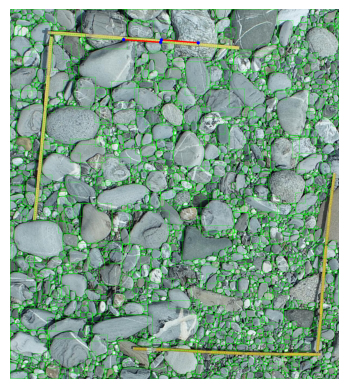

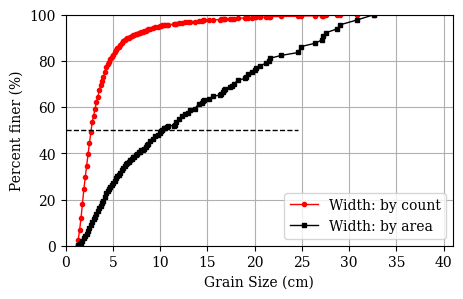

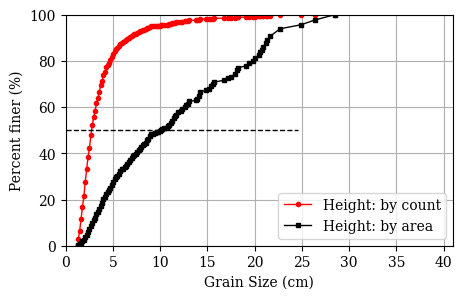

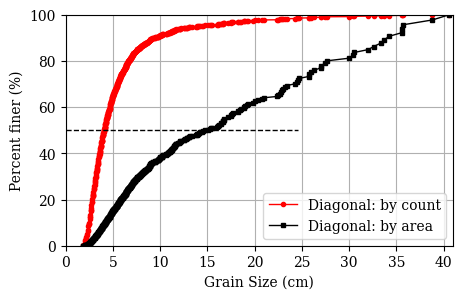

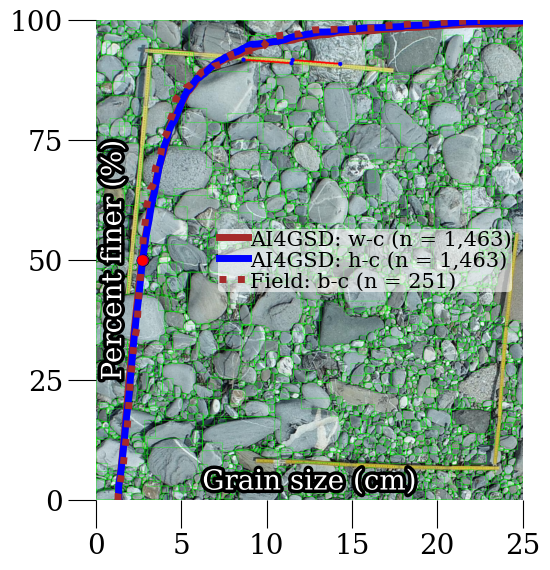

Output folder summary data to: /content/drive/MyDrive/AI4GSD/Demo_Data/20250916_YC_FieldValidateMair2024K1/grains_predicts/20250916_YC_FieldValidateMair2024K1_YOLO11m.1280.20250322_35/Statistics_V3_20250916_YC_FieldValidateMair2024K1_YOLO11m.1280.20250322_35.csv
Total number of grains: 1463, number of grains per photo: 1463.00
Total time: 65.81 s, time per photo 65.81 s

Output all summary data to: /content/drive/MyDrive/AI4GSD/Demo_Data/20250916_YC_FieldValidateMair2024K1/Statistics_V3_20250916_YC_FieldValidateMair2024K1_YOLO11m.1280.20250322_35.csv
Total execution time: 66.42 s


In [10]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.ModelName = 'YOLO11m.1280.20250322'
PP.ImageSizeFactor = 2
PP.YOLOSave = False
PP.SaveFigure = True
PP.SaveOverlayAll = True
PP.OverWriteAll = True
PP.PrintOnScreen = True
PP.GSDWeight = 'c'
PP.GSDAxis = 'wh'
PP.OverlayLableLineWidth = 1
PP.SaveOverlayResolution = 1200
PP.ConfidenceThresholdUser = 0.35
PP.CutGrainSizeMethod = 'wh'
PP.MinimumGrainSize = szmin
PP.OverlayFontSizeScaleFactor = 10
PP.SaveOverlayScaleDotSize = 6
PP.OverlayLegendFontSize = 1.5
PP.OverlayFontLineWidth = 0.5
PP.OverlayGSDLineWidth = 0.5
PP.OverlayD50MarkerSize = 0.8
PP.OverlayFontBoundaryDistanceX = 0.01
PP.OverlayFontBoundaryDistanceY = 0.01
PP.OverlayFontColor = 'white'
PP.OverlayFontColorForeground = 'black'
PP.OverlayLegendLoc = 'best'
PP.OverlayGSDMaxSize = 0.25
PP.OverlayGSDXTickNumber = 6
PP.OverlayGSDYTickNumber = 5
PP.OverlayGSDColor = ['brown','blue','black','orange','cyan','red','purple']
PP.OverlayGSDManualColor = ['brown','blue','black','orange','cyan','blue','purple']
PP.OverlayGSDKey = ['AI4GSD: ','Manual','Field: ']
PP.OverlayGSDLegend = ['w-c','h-c','r-c','area-width','area-height','area-diagonal']
PP.OverlayGSDLegendField = ['b-c','b-c']
PP.OverlayLegendAlpha = 0.6
PP.OverlayLegendFrame = True
PP.OverlayLegendFrame = True
PP.OverlayLegendFaceColor = 'White'
PP.OverlayLegendEdgeColor = 'none'
gsd = AI4GSD.Photo2GSD(PP)

### 6c. Computing relative error between AI4GSD and field for D50

In [11]:
d50x = gsd.D50_x_count_meter.iloc[0]
d50y = gsd.D50_y_count_meter.iloc[0]
d50xy = (d50x + d50y)/2
pe = (d50xy - d50)/d50*100
print(f'Relative error between AI and field measurement is {pe:.2f}%')

Relative error between AI and field measurement is 1.17%


### 7. Applying quality control

In [12]:
gsdqc, stqc = AI4GSD.qualityControl(PhotoDir)


Quality control summary for 20250916_YC_FieldValidateMair2024K1:
Photos: time 0.0 s, area 3.6 m2, valid area 3.6 m2 (100.0%), frame 1, valid frame 1 (100.0%)
Photos: grain number 1463, number per image 1463.0; efficiency 0.0 m2/s, 0.0 grains/s
